# 04. Final evaluation and error analysis

In the previous notebooks I compared logistic regression, a decision tree and kNN with 5-fold cross-validation on the train set only. The final model is logistic regression: TF-IDF on character 1-3 grams, C=10, balanced class weights (CV macro-F1 ≈ 0.889).

Here I:
1. Recreate the same cleaned data and the same stratified 80/20 split (same `random_state`), so the test set is exactly the one I have not touched before.
2. Train the final model on the whole train set and evaluate it **once** on the test set (macro-F1, precision and recall per class).
3. Compare the test score with the CV score to check that the estimate is consistent.
4. Analyze errors: read misclassified reviews and check whether the mistakes come from the model or from noisy labels.

No model selection or tuning is done in this notebook, so the test score is an honest estimate of how the model works on new reviews.

In [21]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
df = pd.read_csv("../data/waimai_10k.csv") 
mask = df.duplicated(subset="review", keep=False)
df.loc[mask, "label"] = 1
df = df.drop_duplicates(subset="review").reset_index(drop=True)
from sklearn.model_selection import StratifiedKFold, train_test_split
X = df["review"]
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size =0.2,
    random_state=42,
    stratify=y
)
from sklearn.metrics import make_scorer, fbeta_score, recall_score
from sklearn.metrics import precision_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f2_neg = make_scorer(fbeta_score, beta=2, pos_label=0)


In [22]:
print(X_train.shape)
print(X_test.shape)

(9584,)
(2396,)


In [23]:


final_model = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(1, 3))),
    ("clf", LogisticRegression(C=10, class_weight="balanced", max_iter=1000)),
])
final_model.fit(X_train, y_train)
pred = final_model.predict(X_test)

In [24]:
from sklearn.metrics import classification_report, f1_score
report = classification_report(
    y_test, pred,
    target_names=["negative (0)", "positive (1)"],
    output_dict=True,
)
report_df = pd.DataFrame(report).T.round(3)
report_df

,precision,recall,f1-score,support
negative (0),0.909,0.944,0.927,1596.0
positive (1),0.880,0.812,0.845,800.0
accuracy,0.900,0.900,0.900,0.9
macro avg,0.895,0.878,0.886,2396.0
weighted avg,0.899,0.900,0.899,2396.0


In [25]:
test_f1 = f1_score(y_test, pred, average="macro")
print(f"Test macro-F1: {test_f1:.4f}")
print("CV macro-F1:   0.8895 (std 0.008)")

Test macro-F1: 0.8856
CV macro-F1:   0.8895 (std 0.008)


### Test results

On the held-out test set (2,396 reviews) the final model reaches macro-F1 = 0.886 and accuracy = 0.90, consistent with the CV estimate (0.889 ± 0.008), so tuning did not overfit the train folds. The dummy baseline gets macro-F1 0.40 and accuracy 0.67. For the negative class precision is 0.91 and recall is 0.94; for the positive class precision is 0.88 and recall is 0.81. The model is better at the majority (negative) class, and it makes more false alarms (~150 positive reviews labeled negative) than it misses complaints (~89).

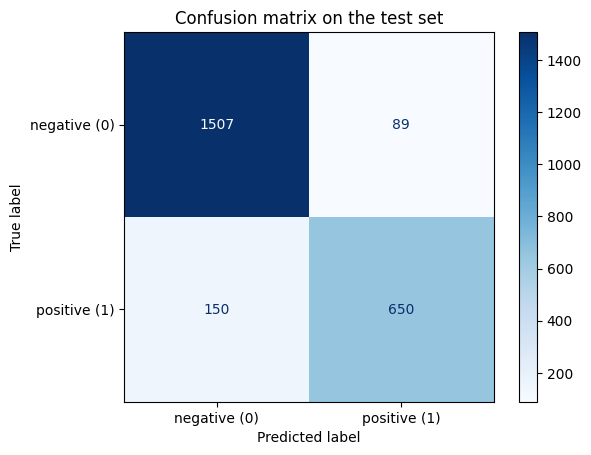

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure()
ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    display_labels=["negative (0)", "positive (1)"],
    cmap="Blues",
    ax=plt.gca(),
)
plt.title("Confusion matrix on the test set")
plt.show()

In [27]:
errors = pd.DataFrame({
    "review": X_test.values,
    "true": y_test.values,
    "pred": pred,
})
errors["proba_pos"] = final_model.predict_proba(X_test)[:, 1]
errors = errors[errors["true"] != errors["pred"]]

false_alarms = errors[(errors["true"] == 1) & (errors["pred"] == 0)]
missed = errors[(errors["true"] == 0) & (errors["pred"] == 1)]
len(false_alarms), len(missed)

(150, 89)

In [28]:
pd.set_option("display.max_colwidth", 200)
false_alarms.sample(15, random_state=1)[["review", "true", "pred", "proba_pos"]]


,review,true,pred,proba_pos
131,包装的是不错的，但是这个肘子卷味道是真的不敢恭维。下次不会来了。,1,0,0.291838
1556,土豆肉丝卷有点咸了……,1,0,0.444612
1183,买了一份拉面都没有餐具呀怎么吃,1,0,0.027457
187,这个味道一般，不喜欢,1,0,0.068503
2108,没有想到鸡柳沙拉里面有那么多沙拉酱，我本来就感冒了不想吃太腻的，没想到还是吃了。。。,1,0,0.037111
1007,我点的一个扁豆焖面套餐，还单点了一个奶茶，还有一个煎饼，结果只给我了一杯奶茶，套餐的可乐没给我，客服电话还老打不通，送餐师傅也不容易，算了，习惯好评。希望店家能在网页上留下送餐师傅的电话好即时联系。,1,0,0.117726
2248,已经养成习惯在他们家订饭,1,0,0.210166
799,发票为什么少了30元,1,0,0.019347
423,很快，而且送了番茄酱和纸巾,1,0,0.474020
1950,味道还可以。,1,0,0.434819


### Error analysis: false alarms (positive reviews predicted as negative)

I read 15 random reviews from the 150 false alarms. About 9 of them are actually complaints or criticism (e.g. "won't order again", "no cutlery", "too sweet") labeled as positive, so these are likely label errors rather than model errors; one review even says the author habitually gives good ratings anyway. Only ~3-5 are real model mistakes, mostly implicitly positive texts without sentiment words (e.g. "I've got used to ordering from them"). This suggests the labels partly reflect star ratings instead of the text, and the test score underestimates the model's real quality. This is based on a small sample.

In [29]:
missed.sample(15, random_state=1)[["review", "true", "pred", "proba_pos"]]

,review,true,pred,proba_pos
1354,挺好的…但是没有在店里好吃…,0,1,0.907143
1743,还行。就是有点凉了,0,1,0.500136
1209,"豆角很老,很柴",0,1,0.551241
1214,超时！但是态度挺好。说是第一天上班，勉强给个三星。,0,1,0.642915
2016,快点吧！饿了,0,1,0.505785
1942,饼不错，味道也可以，就是夹的菜有点少。送餐速度也挺快。,0,1,0.920841
1321,送餐很准时,0,1,0.862913
934,"味道不错,就是太慢了,真的很慢",0,1,0.595059
955,"下次能送早点就好啦,快饿过劲啦",0,1,0.799301
914,送的有点慢，味道很好！,0,1,0.912329


### Error analysis: missed complaints (negative reviews predicted as positive)

I read 15 random reviews from the 89 missed complaints. About 5 are real model mistakes: implicit criticism without typical sentiment words (e.g. "the beans are tough") or negation ("not really to my taste"). About 5 are mixed reviews (praise plus a complaint about delivery or temperature), 4 look like label errors (e.g. "delivery was on time" labeled negative), and 1 is too short to judge.

## Overall conclusion of the error analysis

Over the 30 reviews I read (15 false alarms + 15 missed complaints), roughly 13 look like label errors, 6 are mixed, and about 10 are real model mistakes. The most confident errors are mostly label problems. The labels may partly come from star ratings rather than the text, so the test macro-F1 (0.886) probably underestimates the model's real quality. This is based on a small sample read by one person.

Ideas for improvement: clean noisy labels, use word-level or contextual features (e.g. a pretrained Chinese model), and handle mixed reviews explicitly (e.g. a third "neutral" class).